# Adult income

Inspect the UCI Adult dataset (id 2), also called Census Income. Each row is one adult from the 1994 US Census. The features describe the person (age, education, marital status, occupation, race, sex, country of birth) and their work (employer type, hours per week, capital gains and losses). `income` is whether the person earns more than $50K a year.

A logistic regression is the baseline. Later experiments change one thing at a time.

## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.

In [1]:
import ssl

_create_default_context = ssl.create_default_context


def _create_default_context_windows_store(*args, **kwargs):
    '''Use the OS trust store, which includes the Avast scanning root.'''
    return _create_default_context()


ssl.create_default_context = _create_default_context_windows_store

## Load the dataset

The download joins the two original files: `adult.data` (32,561 rows) and `adult.test` (16,281 rows). The test file writes its labels with a trailing period (`>50K.`), so `income` arrives with four values for two classes. The period is stripped.

Missing values also arrive two ways: as empty cells and as the text `?`. Every `?` becomes a real missing value, so both are counted together.

In [2]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)

df = X.copy()
df["income"] = y.iloc[:, 0].str.rstrip(".")
df = df.replace("?", np.nan)

print(df.shape)
print(list(df.columns))

{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

## Inspect the data

`df` is 48,842 adults: 14 features plus the target `income`. Six columns are numbers and the other eight are text categories. Three columns have missing values: `occupation` (2,809), `workclass` (2,799), and `native-country` (857). 3,620 rows (7.4%) miss at least one of them.

`education` and `education-num` are the same information twice: each education level has exactly one number, from 1 (Preschool) to 16 (Doctorate). `fnlwgt` is a census sampling weight, the number of people the row stands for, not a property of the person. `capital-gain` is zero for 92% of adults and tops out at 99,999 for 244 of them, a value that looks like a cap. `capital-loss` is zero for 95%.

In [3]:
print(df.head())
df.info()
print(df.describe())
print(df.isnull().sum())

   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-States  <=50K  
1             0             0             

## Investigate the target

`income` is `<=50K` for 37,155 adults (76.1%) and `>50K` for 11,687 adults (23.9%). The classes are imbalanced, though less than in bank marketing: always answering `<=50K` would already be right 76% of the time, so that is the floor accuracy has to beat.

In [4]:
print(df["income"].value_counts())
print(df["income"].value_counts(normalize=True))

income
<=50K    37155
>50K     11687
Name: count, dtype: int64
income
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64


### Correlations

Text columns are turned into numbers (missing values become their own category first) and `income` becomes 0 or 1, so every column can enter a correlation with the target.

In [5]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

encoded = df.copy()
for col in encoded.select_dtypes(exclude="number").columns:
    encoded[col] = encoded[col].fillna("missing").astype("category").cat.codes
encoded["income"] = (df["income"] == ">50K").astype(int)

corr = encoded.corr()
print(corr["income"].drop("income").sort_values(key=abs, ascending=False).round(3))

education-num     0.333
relationship     -0.253
age               0.230
hours-per-week    0.228
capital-gain      0.223
sex               0.215
marital-status   -0.199
capital-loss      0.148
education         0.080
race              0.071
workclass        -0.061
native-country    0.021
occupation        0.007
fnlwgt           -0.006
Name: income, dtype: float64


`education-num` is the strongest correlate of `income` (0.33), followed by `relationship` (-0.25), `age` (0.23), `hours-per-week` (0.23), `capital-gain` (0.22), `sex` (0.22), and `marital-status` (-0.20). `fnlwgt` is close to zero (-0.006), as expected for a sampling weight.

`education` (0.08) scores far below `education-num` (0.33) though they hold the same information. Its codes are alphabetical, so 10th, 11th, and Bachelors sit next to each other, and a straight-line correlation cannot see the real order. The same caution applies to every text column: a weak value does not mean a column is useless.

### Rates by group

Correlations on alphabetical codes are rough, so the share of `>50K` inside each group of the three strongest text columns is shown directly.

In [6]:
high = df["income"] == ">50K"
for col in ["relationship", "marital-status", "sex"]:
    print(high.groupby(df[col]).agg(["mean", "size"]).sort_values("mean", ascending=False).round(3))

                 mean   size
relationship                
Wife            0.469   2331
Husband         0.449  19716
Not-in-family   0.101  12583
Unmarried       0.060   5125
Other-relative  0.035   1506
Own-child       0.015   7581
                        mean   size
marital-status                     
Married-civ-spouse     0.446  22379
Married-AF-spouse      0.378     37
Divorced               0.101   6633
Married-spouse-absent  0.092    628
Widowed                0.084   1518
Separated              0.065   1530
Never-married          0.045  16117
         mean   size
sex                 
Male    0.304  32650
Female  0.109  16192


Being married is the clearest split. 44.6% of `Married-civ-spouse` adults earn more than $50K, against 4.5% of `Never-married` adults (the 37 armed-forces spouses, `Married-AF-spouse`, are too few to compare) and about 10% of divorced or widowed ones. `relationship` repeats this: husbands (44.9%) and wives (46.9%) are far above own children (1.5%). Across all adults, 30.4% of men and 10.9% of women earn more than $50K.

`relationship` and `marital-status` overlap heavily, and `relationship` also encodes sex through husband and wife.

## Visualise relationships

The pairplot crosses age, years of education (`education-num`), hours per week, and capital gain, colored by `income`. It uses a random sample of 2,000 adults so the plot stays readable and fast.

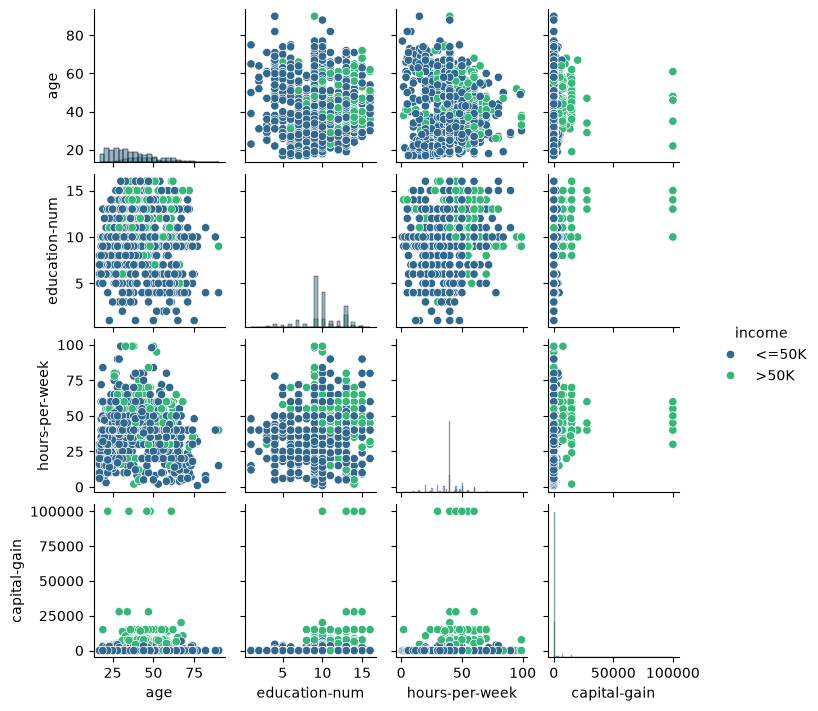

In [7]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df[["age", "education-num", "hours-per-week", "capital-gain", "income"]].sample(2000, random_state=42)

sns.pairplot(plot_df, hue="income", diag_kind="hist", height=1.8, palette="viridis")
plt.show()

Education and age carry most of the visible signal. Adults earning more than $50K sit mostly at 9 years of education or more and at ages between about 30 and 60, while the young and the less educated are almost all below $50K. Hours per week has a tall spike at 40, the standard full-time week, and the higher earners lean toward 40 hours or more.

Capital gain is zero for almost everyone, so its histogram is a single bar at 0. When it is not zero, it is a strong signal: nearly every point above about 7,000, and all of the capped 99,999 values, belong to adults earning more than $50K. The scatter plots overlap heavily, so no single pair of columns separates the classes on its own.

## Train and test split

Hold out 20% of the adults and stratify on `income`, so the 24% earning more than $50K is the same in both sets.

The split gives 39,073 training rows and 9,769 test rows. Adults earning more than $50K are 23.93% of both sets.

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="income")
y = (df["income"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(39073, 14) (9769, 14)
0.23927008420136667 0.23932848807452145


## Baseline

A logistic regression inside a pipeline, kept as plain as possible. All 14 columns are used as they are, including `fnlwgt` and both `education` and `education-num`. Each text column is turned into numbers with an ordinal encoder, and its missing values become their own category `missing` first. Nothing is one-hot encoded yet. Every column is then scaled.

The numbers given to the categories are alphabetical, so they have no real order. This is a crude encoding that later experiments can improve.

Accuracy is reported, but because only 24% of adults earn more than $50K, precision, recall, and ROC AUC are reported too.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

categorical = X.select_dtypes(exclude="number").columns

encode = ColumnTransformer([
    (
        "cat",
        make_pipeline(
            SimpleImputer(strategy="constant", fill_value="missing"),
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        ),
        categorical,
    ),
], remainder="passthrough")

baseline = make_pipeline(encode, StandardScaler(), LogisticRegression(max_iter=10000))
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
proba = baseline.predict_proba(X_test)[:, 1]
print("accuracy:", accuracy_score(y_test, pred))
print("always <=50K:", 1 - y_test.mean())
print("roc auc:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["<=50K", ">50K"]))

accuracy: 0.8231139318251612
always <=50K: 0.7606715119254785
roc auc: 0.8502315974775174
[[6979  452]
 [1276 1062]]
              precision    recall  f1-score   support

       <=50K       0.85      0.94      0.89      7431
        >50K       0.70      0.45      0.55      2338

    accuracy                           0.82      9769
   macro avg       0.77      0.70      0.72      9769
weighted avg       0.81      0.82      0.81      9769



The baseline scores 0.823 accuracy on the 9,769 held-out adults, 6.2 points above always answering `<=50K` (0.761). ROC AUC is 0.850, so the model ranks higher earners above the others fairly well.

The confusion matrix shows where the accuracy comes from. Of 7,431 adults earning $50K or less, 6,979 are right (recall 0.94). Of 2,338 earning more, only 1,062 are found (recall 0.45), and 1,276 are missed. When the model predicts `>50K` it is right 70% of the time (1,062 of 1,514).

F1 is 0.89 for `<=50K` and 0.55 for `>50K`. There are about three times more adults at or below $50K, so the model leans that way, and the alphabetical codes hide the real pattern in columns like `education`, `marital-status`, and `relationship`. Recall on `>50K` is the number to improve in the experiments.

## One change at a time

Every experiment below changes one thing from the one before it and is scored on the same 9,769 held-out rows. The helper keeps each result so they can be compared at the end.

In [10]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import OneHotEncoder

results = {}


def record(name, y_true, pred, proba):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, pred, pos_label=1, average="binary"
    )
    results[name] = {
        "accuracy": accuracy_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "precision_>50K": precision,
        "recall_>50K": recall,
        "f1_>50K": f1,
    }


def report(name, model, X_tr, X_te, y_tr=None):
    model.fit(X_tr, y_train if y_tr is None else y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    record(name, y_test, pred, proba)
    print(name)
    print(pd.Series(results[name]).round(3).to_string())
    print(confusion_matrix(y_test, pred))


def one_hot_logreg(X_tr):
    text = X_tr.select_dtypes(exclude="number").columns
    encode = ColumnTransformer([
        (
            "cat",
            make_pipeline(
                SimpleImputer(strategy="constant", fill_value="missing"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            text,
        ),
    ], remainder="passthrough")
    return make_pipeline(encode, StandardScaler(), LogisticRegression(max_iter=10000))


record("baseline: logreg, ordinal", y_test, pred, proba)

### One-hot encoding

Every text column gets one column per category, so the model no longer treats the alphabetical codes as an order. Missing values are still their own category. The columns are the same 14, and the model is the same logistic regression.

In [11]:
report("one-hot", one_hot_logreg(X_train), X_train, X_test)

one-hot
accuracy          0.851
roc_auc           0.905
precision_>50K    0.731
recall_>50K       0.600
f1_>50K           0.659
[[6915  516]
 [ 936 1402]]


One-hot encoding is a large step. Accuracy goes from 0.823 to 0.851, ROC AUC from 0.850 to 0.905, recall on `>50K` from 0.454 to 0.600, and F1 from 0.551 to 0.659. Precision rises too, from 0.701 to 0.731. The model now finds 1,402 of the 2,338 higher earners, up from 1,062, while false alarms only rise from 452 to 516.

The alphabetical codes were forcing a straight-line order on columns like `marital-status`, `relationship`, and `occupation`. With one column per category, each status can carry its own weight: married can push up while never-married pushes down, wherever they fall in the alphabet.

### Deduplicate

Only the training rows are deduplicated. The held-out rows stay the same, so this score can be compared with the ones before it. A row counts as a duplicate when every feature and `income` match an earlier row.

In [12]:
duplicated = X_train.assign(income=y_train).duplicated()
print("duplicate training rows:", duplicated.sum())

X_train_dedup = X_train[~duplicated]
y_train_dedup = y_train[~duplicated]
print(X_train_dedup.shape)

report("one-hot, deduplicated", one_hot_logreg(X_train_dedup), X_train_dedup, X_test, y_train_dedup)

duplicate training rows: 35
(39038, 14)


one-hot, deduplicated
accuracy          0.851
roc_auc           0.905
precision_>50K    0.731
recall_>50K       0.600
f1_>50K           0.659
[[6915  516]
 [ 935 1403]]


35 of the 39,073 training rows are exact duplicates, under 0.1%. Removing them changes almost nothing: one more higher earner is found (1,403 instead of 1,402), and every rounded score stays the same. The duplicates are probably different people who happen to share every answer, and 35 rows are too few to pull the weights either way.

### Drop `education`

`education` and `education-num` hold the same information, one level for each number. `education-num` keeps the real order, so `education` is dropped.

In [13]:
X_train_noedu = X_train_dedup.drop(columns="education")
X_test_noedu = X_test.drop(columns="education")

report(
    "one-hot, deduplicated, no education",
    one_hot_logreg(X_train_noedu),
    X_train_noedu,
    X_test_noedu,
    y_train_dedup,
)

one-hot, deduplicated, no education
accuracy          0.851
roc_auc           0.905
precision_>50K    0.729
recall_>50K       0.602
f1_>50K           0.660
[[6908  523]
 [ 930 1408]]


Dropping `education` barely moves the scores. Recall on `>50K` goes from 0.600 to 0.602 (5 more found) and precision from 0.731 to 0.729 (7 more false alarms). Accuracy and ROC AUC are unchanged at 0.851 and 0.905.

That is expected. With one-hot encoding, the 16 `education` columns carry exactly what `education-num` already says, so the model loses nothing when they go. The table is smaller and nothing is said twice.

### Married or not

`marital-status` is replaced by a single 0/1 column `married`. Every `Married-*` status counts as married: `Married-civ-spouse`, `Married-AF-spouse`, and `Married-spouse-absent`. `Separated`, `Divorced`, `Widowed`, and `Never-married` count as not married.

In [14]:
def married_flag(X):
    out = X.drop(columns="marital-status")
    out["married"] = X["marital-status"].str.startswith("Married").astype(int)
    return out


X_train_married = married_flag(X_train_noedu)
X_test_married = married_flag(X_test_noedu)
print(X_train_married["married"].mean())

report(
    "one-hot, deduplicated, no education, married flag",
    one_hot_logreg(X_train_married),
    X_train_married,
    X_test_married,
    y_train_dedup,
)

0.4731287463497105


one-hot, deduplicated, no education, married flag
accuracy          0.851
roc_auc           0.905
precision_>50K    0.729
recall_>50K       0.602
f1_>50K           0.659
[[6907  524]
 [ 930 1408]]


47.3% of the training adults are married under this definition.

Replacing `marital-status` with `married` changes one prediction: one more adult earning $50K or less is called `>50K`. Every other score rounds to the same value. The seven statuses were already splitting mostly into married and not married, and `relationship` still holds husband and wife, which says the same thing for most married adults. One column now does the work of seven, with no loss.

### Random forest

Same table as the last step: one-hot, deduplicated, no `education`, and the `married` column. The model changes to a forest of trees that each see a bootstrap sample of the rows and a random subset of columns at each split. Scaling is dropped because trees only compare each column to a threshold. The settings are scikit-learn's defaults (100 trees, grown until their leaves are pure).

In [15]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier


def one_hot_trees(X_tr, model):
    text = X_tr.select_dtypes(exclude="number").columns
    encode = ColumnTransformer([
        (
            "cat",
            make_pipeline(
                SimpleImputer(strategy="constant", fill_value="missing"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            text,
        ),
    ], remainder="passthrough")
    return make_pipeline(encode, model)


report(
    "random forest",
    one_hot_trees(X_train_married, RandomForestClassifier(random_state=42, n_jobs=-1)),
    X_train_married,
    X_test_married,
    y_train_dedup,
)

random forest
accuracy          0.859
roc_auc           0.907
precision_>50K    0.739
recall_>50K       0.633
f1_>50K           0.682
[[6909  522]
 [ 857 1481]]


The forest beats the logistic regression on every score. Accuracy goes from 0.851 to 0.859, recall on `>50K` from 0.602 to 0.633, precision from 0.729 to 0.739, and F1 from 0.659 to 0.682. It finds 1,481 of the 2,338 higher earners, 73 more than before, with two fewer false alarms (522).

ROC AUC barely moves (0.905 to 0.907), so the forest does not rank adults much better overall. Its gain is around the 0.5 threshold, where combinations of columns, such as married and many hours, can be picked up by the trees but not by a single straight-line score.

### Gradient boosting

Same table, a different model. Gradient boosting builds many small trees one after another, and each new tree is fit to the mistakes of the ones before it. The settings are scikit-learn's defaults (100 trees of depth 3).

In [16]:
report(
    "gradient boosting",
    one_hot_trees(X_train_married, GradientBoostingClassifier(random_state=42)),
    X_train_married,
    X_test_married,
    y_train_dedup,
)

gradient boosting
accuracy          0.869
roc_auc           0.922
precision_>50K    0.795
recall_>50K       0.612
f1_>50K           0.692
[[7063  368]
 [ 907 1431]]


Gradient boosting is the best model so far. Accuracy is 0.869, ROC AUC 0.922 (up from 0.905 and 0.907), and F1 on `>50K` 0.692.

It wins through precision rather than recall. When it predicts `>50K` it is right 79.5% of the time, against 73.9% for the forest, and false alarms drop from 522 to 368. Recall is 0.612 (1,431 found), between the logistic regression (0.602) and the forest (0.633). The higher ROC AUC says its ranking is the best of the three, so a lower threshold could trade some of that precision for more recall.

### Lower the threshold on gradient boosting

Gradient boosting has the best ROC AUC, so its ranking is good, but at the default threshold of 0.5 it misses many higher earners. A lower threshold calls more adults `>50K`: recall should rise and precision fall.

The threshold is chosen on the training rows, not on the held-out ones. Stratified 5-fold cross-validation gives every training adult a probability from a model that did not see them. Each threshold from 0.20 to 0.50 is scored on those probabilities, and the one with the best F1 on `>50K` is kept. The model is then fit on all training rows and scored once on the held-out rows at that threshold.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

gb = one_hot_trees(X_train_married, GradientBoostingClassifier(random_state=42))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_proba = cross_val_predict(gb, X_train_married, y_train_dedup, cv=cv, method="predict_proba")[:, 1]

rows = []
for threshold in np.arange(0.20, 0.51, 0.05):
    cv_pred = (cv_proba >= threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_train_dedup, cv_pred, pos_label=1, average="binary"
    )
    rows.append({
        "threshold": round(threshold, 2),
        "accuracy": accuracy_score(y_train_dedup, cv_pred),
        "precision_>50K": precision,
        "recall_>50K": recall,
        "f1_>50K": f1,
    })
sweep = pd.DataFrame(rows).set_index("threshold")
print("Cross-validated scores on the training rows")
print(sweep.round(3))

best = sweep["f1_>50K"].idxmax()
print("best threshold by F1:", best)

Cross-validated scores on the training rows
           accuracy  precision_>50K  recall_>50K  f1_>50K
threshold                                                
0.20          0.809           0.565        0.888    0.690
0.25          0.829           0.601        0.850    0.704
0.30          0.846           0.643        0.799    0.713
0.35          0.856           0.682        0.749    0.714
0.40          0.863           0.722        0.697    0.710
0.45          0.866           0.757        0.648    0.698
0.50          0.866           0.784        0.606    0.684
best threshold by F1: 0.35


On the training rows, lowering the threshold trades precision for recall as expected. At 0.50, recall on `>50K` is 0.606 and precision 0.784. At 0.20, recall reaches 0.888 but precision falls to 0.565.

F1 peaks at 0.35 (0.714), with 0.30 almost level (0.713). The curve is flat between 0.30 and 0.40, so the exact choice matters little. 0.35 is kept.

In [18]:
gb.fit(X_train_married, y_train_dedup)
gb_proba = gb.predict_proba(X_test_married)[:, 1]
gb_pred = (gb_proba >= best).astype(int)

name = f"gradient boosting, threshold {best:.2f}"
record(name, y_test, gb_pred, gb_proba)
print(name)
print(pd.Series(results[name]).round(3).to_string())
print(confusion_matrix(y_test, gb_pred))

gradient boosting, threshold 0.35
accuracy          0.858
roc_auc           0.922
precision_>50K    0.689
recall_>50K       0.744
f1_>50K           0.716
[[6646  785]
 [ 598 1740]]


At 0.35 on the held-out rows, recall on `>50K` rises from 0.612 to 0.744 and F1 from 0.692 to 0.716, the best F1 so far. The model finds 1,740 of the 2,338 higher earners, 309 more than at 0.5, and misses 598 instead of 907.

The price is precision: false alarms rise from 368 to 785, and precision falls from 0.795 to 0.689. Accuracy drops from 0.869 to 0.858, because more of the common class is now called `>50K`. ROC AUC stays at 0.922: the model and its ranking are the same, only the cut-off moved.

These held-out scores are close to the cross-validated ones at 0.35 (precision 0.682, recall 0.749, F1 0.714), so the threshold chosen on the training rows carries over.

### Random search over ranges

So far every model used scikit-learn's default settings. Here each setting gets a range instead of a short list, and `RandomizedSearchCV` draws random combinations from those ranges. Every draw is scored by stratified 5-fold cross-validation on the training rows, never on the held-out ones. Scales that work by multiples (`learning_rate`, `l2_regularization`, `C`, `gamma`) are sampled on a log scale.

The table is the same as the last step: one-hot, deduplicated, no `education`, and the `married` column.

**Gradient boosting.** `HistGradientBoostingClassifier`, a faster version of the same idea, searched over `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, and `l2_regularization`, with 25 draws. The number of trees is not searched: `max_iter` is set to 1000 and early stopping decides how many to grow. Draws are scored by ROC AUC, which does not depend on a threshold.

In [19]:
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

search_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

hgb_search = RandomizedSearchCV(
    one_hot_trees(
        X_train_married,
        HistGradientBoostingClassifier(
            max_iter=1000, early_stopping=True, n_iter_no_change=15, random_state=42
        ),
    ),
    param_distributions={
        "histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.3),
        "histgradientboostingclassifier__max_leaf_nodes": randint(15, 255),
        "histgradientboostingclassifier__min_samples_leaf": randint(5, 60),
        "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    },
    n_iter=25,
    cv=search_folds,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1,
)
hgb_search.fit(X_train_married, y_train_dedup)

print("best cross-validated ROC AUC:", round(hgb_search.best_score_, 4))
print({k.split("__")[1]: round(float(v), 4) for k, v in hgb_search.best_params_.items()})
print("trees grown:", hgb_search.best_estimator_[-1].n_iter_)

report(
    "gradient boosting, random search",
    hgb_search.best_estimator_,
    X_train_married,
    X_test_married,
    y_train_dedup,
)

best cross-validated ROC AUC: 0.9287
{'l2_regularization': 0.8242, 'learning_rate': 0.1615, 'max_leaf_nodes': 19.0, 'min_samples_leaf': 46.0}
trees grown: 136


gradient boosting, random search
accuracy          0.877
roc_auc           0.930
precision_>50K    0.785
recall_>50K       0.666
f1_>50K           0.721
[[7005  426]
 [ 780 1558]]


The searched booster beats the default one on every score except precision. Cross-validated ROC AUC on the training rows is 0.929. On the held-out rows, accuracy goes from 0.869 to 0.877, ROC AUC from 0.922 to 0.930, recall on `>50K` from 0.612 to 0.666, and F1 from 0.692 to 0.721. It finds 1,558 of the 2,338 higher earners, 127 more than before, for 58 more false alarms (426). Precision dips slightly, from 0.795 to 0.785.

The chosen settings are `learning_rate` 0.162, `max_leaf_nodes` 19, `min_samples_leaf` 46, and `l2_regularization` 0.82, with early stopping at 136 trees. Two of them sit near the edge of their range: 19 leaves is close to the lowest allowed (15) and a minimum of 46 per leaf is close to the highest (59). The search prefers small, cautious trees, so a second search could look in that corner more closely.

In [20]:
from sklearn.metrics import f1_score

hgb_cv_proba = cross_val_predict(
    hgb_search.best_estimator_, X_train_married, y_train_dedup, cv=search_folds, method="predict_proba"
)[:, 1]
hgb_f1 = {
    float(round(t, 2)): f1_score(y_train_dedup, (hgb_cv_proba >= t).astype(int))
    for t in np.arange(0.20, 0.51, 0.05)
}
hgb_best = max(hgb_f1, key=hgb_f1.get)
print({t: round(f, 3) for t, f in hgb_f1.items()})
print("best threshold by F1:", hgb_best)

hgb_proba = hgb_search.best_estimator_.predict_proba(X_test_married)[:, 1]
hgb_pred = (hgb_proba >= hgb_best).astype(int)

name = f"gradient boosting, random search, threshold {hgb_best:.2f}"
record(name, y_test, hgb_pred, hgb_proba)
print(name)
print(pd.Series(results[name]).round(3).to_string())
print(confusion_matrix(y_test, hgb_pred))

{0.2: 0.705, 0.25: 0.717, 0.3: 0.724, 0.35: 0.729, 0.4: 0.726, 0.45: 0.722, 0.5: 0.713}
best threshold by F1: 0.35
gradient boosting, random search, threshold 0.35
accuracy          0.862
roc_auc           0.930
precision_>50K    0.685
recall_>50K       0.782
f1_>50K           0.730
[[6591  840]
 [ 510 1828]]


The same procedure as before, cross-validating on the training rows, picks 0.35 again (F1 0.729). On the held-out rows, recall rises to 0.782 and F1 to 0.730, the best F1 so far. The model finds 1,828 of the 2,338 higher earners and misses 510, against 598 for the default booster at the same threshold. The price is the same one as before: 840 false alarms, precision 0.685, and accuracy 0.862.

ROC AUC is 0.930 at every threshold. The search moved the ranking from 0.922 to 0.930, and the threshold moves the cut-off along it.

**Support vector classifier.** An SVC with an RBF kernel draws the class boundary with the widest margin it can find. `C` is how strictly it must classify training adults correctly, and `gamma` is how far each adult's influence reaches. Both are searched over wide ranges. An SVC on 39,000 rows is slow and needs scaled columns, so the search runs on a stratified sample of 6,000 training adults with 3 folds and 12 draws, and the best settings are then fit on all the training rows. It has no probabilities by default, so ROC AUC and the score are taken from its `decision_function`, and its threshold stays at the default.

In [21]:
import time
from sklearn.svm import SVC

svc_X, _, svc_y, _ = train_test_split(
    X_train_married, y_train_dedup, train_size=6000, random_state=42, stratify=y_train_dedup
)


def one_hot_svc(X_tr):
    text = X_tr.select_dtypes(exclude="number").columns
    encode = ColumnTransformer([
        (
            "cat",
            make_pipeline(
                SimpleImputer(strategy="constant", fill_value="missing"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            text,
        ),
    ], remainder="passthrough")
    return make_pipeline(encode, StandardScaler(), SVC(kernel="rbf"))


svc_search = RandomizedSearchCV(
    one_hot_svc(X_train_married),
    param_distributions={
        "svc__C": loguniform(0.1, 100),
        "svc__gamma": loguniform(1e-4, 1e-1),
    },
    n_iter=12,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1,
)
start = time.time()
svc_search.fit(svc_X, svc_y)
print(f"search on 6,000 rows: {time.time() - start:.0f}s")
print("best cross-validated ROC AUC:", round(svc_search.best_score_, 4))
print({k.split("__")[1]: round(float(v), 5) for k, v in svc_search.best_params_.items()})

svc = one_hot_svc(X_train_married).set_params(**svc_search.best_params_)
start = time.time()
svc.fit(X_train_married, y_train_dedup)
print(f"final fit on all training rows: {time.time() - start:.0f}s")

svc_score = svc.decision_function(X_test_married)
svc_pred = (svc_score > 0).astype(int)
record("SVC, random search", y_test, svc_pred, svc_score)
print("SVC, random search")
print(pd.Series(results["SVC, random search"]).round(3).to_string())
print(confusion_matrix(y_test, svc_pred))

search on 6,000 rows: 5s
best cross-validated ROC AUC: 0.8927
{'C': 31.42881, 'gamma': 0.00043}


final fit on all training rows: 33s


SVC, random search
accuracy          0.856
roc_auc           0.905
precision_>50K    0.744
recall_>50K       0.606
f1_>50K           0.668
[[6944  487]
 [ 921 1417]]


The search on 6,000 adults takes 5 seconds and picks `C` 31.4 and `gamma` 0.00043. Its cross-validated ROC AUC (0.893) is lower than the one for gradient boosting, but it comes from 3 folds on a sample of 6,000, so it is not comparable with the held-out scores below.

On the held-out rows, the SVC scores accuracy 0.856, ROC AUC 0.905, precision 0.744, recall 0.606, and F1 0.668. That is almost the same as the one-hot logistic regression (0.851, 0.905, 0.729, 0.602, 0.659): slightly higher accuracy and precision, and the same ranking. A curved boundary finds little the straight line missed here. Gradient boosting stays well ahead (ROC AUC 0.930, F1 0.721), and the final fit on all rows takes 34 seconds, against a few seconds for the booster. Its threshold is left at the default, so recall of 0.606 could be raised in the same way as for the booster.

### Comparison

In [22]:
print(pd.DataFrame(results).T.round(3))

                                                   accuracy  roc_auc  precision_>50K  recall_>50K  f1_>50K
baseline: logreg, ordinal                             0.823    0.850           0.701        0.454    0.551
one-hot                                               0.851    0.905           0.731        0.600    0.659
one-hot, deduplicated                                 0.851    0.905           0.731        0.600    0.659
one-hot, deduplicated, no education                   0.851    0.905           0.729        0.602    0.660
one-hot, deduplicated, no education, married flag     0.851    0.905           0.729        0.602    0.659
random forest                                         0.859    0.907           0.739        0.633    0.682
gradient boosting                                     0.869    0.922           0.795        0.612    0.692
gradient boosting, threshold 0.35                     0.858    0.922           0.689        0.744    0.716
gradient boosting, random search     

One-hot encoding is the largest single gain: it lifts accuracy from 0.823 to 0.851, ROC AUC from 0.850 to 0.905, and recall on `>50K` from 0.454 to 0.600. Deduplicating, dropping `education`, and collapsing `marital-status` into `married` each keep the scores within a few adults of the step before. They make the table simpler without costing anything.

On that simpler table, trees do better than a straight line. Gradient boosting with default settings has ROC AUC 0.922, and a random search over its settings lifts it to 0.930, with accuracy 0.877 and F1 0.721 at the default threshold. An SVC with searched settings only matches the logistic regression (ROC AUC 0.905) and is slower to fit.

Lowering the threshold to 0.35, chosen by cross-validation on the training rows, gives the best balance between finding higher earners and false alarms. For the searched booster it gives recall 0.782 and F1 0.730: it misses 510 of the 2,338 higher earners instead of 780, at the cost of 840 false alarms instead of 426. Which threshold is better depends on whether a missed higher earner or a false alarm costs more.

## Conclusion

The table has 48,842 adults from the 1994 US Census with 14 features, and 23.9% of them earn more than $50K a year. The stratified 80/20 split gave 39,073 training rows and 9,769 test rows, with the same 23.9% in both. Always answering `<=50K` is right 76.1% of the time.

The baseline, a logistic regression with alphabetical category codes, scored 0.823 accuracy and 0.850 ROC AUC, but found only 45.4% of the higher earners (F1 0.551). One-hot encoding the categories was the largest single gain: 0.851, 0.905, recall 0.600, and F1 0.659. Removing the 35 duplicate training rows, dropping `education` (it repeats `education-num`), and replacing `marital-status` with a married or not column each left the scores within a few adults of the step before, so they simplify the table at no cost.

On that table, the random forest (0.859, 0.907, recall 0.633, F1 0.682) and gradient boosting (0.869, 0.922, recall 0.612, F1 0.692) both beat the logistic regression. Lowering gradient boosting's threshold from 0.5 to 0.35, chosen by cross-validation on the training rows, raised recall to 0.744 and F1 to 0.716. A random search over the booster's settings was worth more than the threshold alone: accuracy 0.877, ROC AUC 0.930, recall 0.666, and F1 0.721 at the default threshold, then recall 0.782 and F1 0.730 at 0.35. An SVC with searched settings scored 0.856, 0.905, recall 0.606, and F1 0.668, the same as the logistic regression, and took longer to fit.

### Which model to use

The searched gradient boosting is the best model. It has the best ranking (ROC AUC 0.930), and it is the pick in the first three cases below. The only thing that changes between them is the threshold, which moves the cut-off along the same ranking.

| If the goal is | Use | Held-out result |
| --- | --- | --- |
| Find as many higher earners as possible, and a false alarm is cheap | Searched gradient boosting at threshold 0.35, or lower | Recall 0.782: 1,828 of 2,338 found, 510 missed, 840 false alarms. |
| The best balance between the two | Searched gradient boosting at threshold 0.35 | Best F1 (0.730), precision 0.685. |
| Few false alarms, or the best overall hit rate | Searched gradient boosting at threshold 0.5 | Accuracy 0.877, precision 0.785, recall 0.666: 1,558 found, 780 missed, 426 false alarms. |
| A model whose weights can be read, or the quickest to build | One-hot logistic regression | ROC AUC 0.905, F1 0.659. It finds 60% of higher earners, 0.025 of ROC AUC below the best. |

For the first row, lowering the threshold further trades more precision for more recall. On the training rows, the default booster went from recall 0.606 and precision 0.784 at 0.5 to recall 0.888 and precision 0.565 at 0.20, and a threshold of 0 would flag everyone: recall 1.0, precision 0.24. Which point is right depends on what a missed higher earner costs next to a false alarm.

Precision at 0.5 is slightly higher for the default booster (0.795) than for the searched one (0.785), but the searched one finds 127 more higher earners, so the default one is not better in any case. The random forest has no case where it wins, and the SVC is never better than the logistic regression, so neither is worth the extra time.

Two cautions. The test set was used to compare every model in this notebook, so a gap of about 0.01 between two models is within what 9,769 adults can show and should not be over-read. The data are also from 1994 and 41 other countries are barely present (90% are born in the United States), so these numbers say how well income can be told in this census extract, not how it would work today.